# NFL Big Data Bowl 2027 — Big Data EDA and MLflow Experiments
**ABDA · Module 3 · Beginner edition**

**Business question:** Do NFL Combine measurements predict how many games a player starts in his career?

| Part | What you do | Spark / MLflow skill |
|---|---|---|
| 0 | Setup and helper functions | Unity Catalog volumes, MLflow settings |
| 1 | Explore the raw data | Load, inspect, filter, group, transformations vs actions |
| 2 | Build the modelling table and EDA | Join, cast, missing values, charts |
| 3 | Run 30 MLflow experiments | Spark ML pipeline, Ridge / Lasso / Elastic Net, solvers |
| 4 | Read the experiments and register the winner | Leaderboard, charts, baseline, Unity Catalog model |

**How to read each section:** a short note says *what the cell does* and *what to look for*. Run cells top to bottom.

> Keep this notebook inside your team's **Git folder**. Do not rename it after you start logging runs.

## Part 0 — Setup

### 0.1 Install the charting library
Plotly draws interactive charts. Run this cell first; it must be in a cell of its own.

In [0]:
%pip install plotly --quiet

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


### 0.2 Settings (the only cell you may need to edit)
**What it does:** names every location used in the notebook in one place, creates a scratch volume, and tells MLflow to register models in Unity Catalog.

**Why the scratch volume?** On serverless compute, Spark ML and MLflow need a Unity Catalog volume for temporary files.

**Where do runs go?** We do **not** call `mlflow.set_experiment`, so every run is saved in this notebook's own experiment, which lives beside the notebook in your Git folder. Open it with the **Experiment (flask) icon** in the right pane.

In [0]:
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from pyspark.sql import functions as F

# ── Names used throughout the notebook ──
CATALOG       = "nfl_bigdatabowl"
SCHEMA        = "nfl_2027"
RAW_VOLUME    = f"/Volumes/{CATALOG}/{SCHEMA}/nfl_2027"   # where the CSV files live
TMP_VOLUME    = f"/Volumes/{CATALOG}/{SCHEMA}/ml_tmp"     # scratch space for Spark ML and MLflow
MODEL_NAME    = f"{CATALOG}.{SCHEMA}.nfl_games_started_lr"
TARGET        = "tg_career_start"                          # what we want to predict
GRID_RUN_NAME = "NFL_LinReg_grid"                          # name of the parent MLflow run
SEED          = 42                                         # makes random splits repeatable

# ── Scratch volume + temp-folder settings (needed on serverless) ──
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.ml_tmp")
for setting in ["SPARKML_TEMP_DFS_PATH", "SPARK_ML_TMP_DFS_PATH", "MLFLOW_DFS_TMP"]:
    os.environ[setting] = TMP_VOLUME

# ── Register models in Unity Catalog ──
mlflow.set_registry_uri("databricks-uc")

# Optional: log to a shared workspace experiment instead of this notebook's experiment.
# This does NOT work if the path is inside a Git folder.
# mlflow.set_experiment("/Users/<your email>/ABDA_M3_NFL_LinReg")

print("Setup complete. Scratch volume:", TMP_VOLUME)

Setup complete. Scratch volume: /Volumes/nfl_bigdatabowl/nfl_2027/ml_tmp


### 0.3 Helper functions
**What it does:** defines four small functions we reuse many times, so later cells stay short.

| Function | What it gives you |
|---|---|
| `load_csv(file)` | A Spark DataFrame from a CSV in the raw volume |
| `null_percent(df, cols)` | % of missing values per column |
| `evaluate(model, df)` | RMSE, MAE and R² of a model on some data |
| `get_grid_runs()` | The parent run id and a tidy table of all experiment runs |

In [0]:
from pyspark.ml.evaluation import RegressionEvaluator


def load_csv(file_name):
    """Read one CSV file from the raw-data volume."""
    return (spark.read
            .option("header", "true")
            .option("inferSchema", "true")
            .csv(f"{RAW_VOLUME}/{file_name}"))


def null_percent(df, columns):
    """Return {column: percentage of rows where the value is missing}."""
    row = df.select([F.avg(F.col(c).isNull().cast("double")).alias(c) for c in columns]).first()
    return {c: round(row[c] * 100, 1) for c in columns}


def evaluate(model, data):
    """Score a fitted model on a DataFrame. Returns {'rmse', 'mae', 'r2'}."""
    predictions = model.transform(data)
    scores = {}
    for metric in ["rmse", "mae", "r2"]:
        evaluator = RegressionEvaluator(labelCol=TARGET, predictionCol="prediction", metricName=metric)
        scores[metric] = evaluator.evaluate(predictions)
    return scores


def get_grid_runs():
    """Find the latest grid run. Returns (parent_run_id, pandas table of its child runs)."""
    parent = mlflow.search_runs(
        filter_string=f"tags.mlflow.runName = '{GRID_RUN_NAME}'",
        order_by=["attributes.start_time DESC"],
        max_results=1,
    )
    if parent.empty:
        raise ValueError("No grid run found yet. Run section 3.3 first.")
    parent_id = parent.loc[0, "run_id"]

    runs = mlflow.search_runs(filter_string=f"tags.mlflow.parentRunId = '{parent_id}'")
    # MLflow names columns like 'metrics.val_rmse'; drop the prefix so they read 'val_rmse'
    runs.columns = [c.split(".", 1)[1] if c.startswith(("params.", "metrics.", "tags.")) else c
                    for c in runs.columns]
    runs = runs.rename(columns={"mlflow.runName": "run_name"})
    runs["regParam"] = pd.to_numeric(runs["regParam"])
    return parent_id, runs


print("Helper functions ready.")

Helper functions ready.


## Part 1 — Explore the raw data

### 1.1 Load all nine datasets
**What it does:** two datasets are Delta tables in Unity Catalog; seven are CSV files in a volume. We keep them in one dictionary called `tables`.

**What to look for:** this cell is instant. Spark is *lazy*: it only records where the data is. Nothing is read until an **action** such as `count()` or `show()`.

In [0]:
tables = {
    # Delta tables registered in Unity Catalog
    "combine_results":         spark.table(f"{CATALOG}.{SCHEMA}.combine_results"),
    "game_tracking_2025":      spark.table(f"{CATALOG}.{SCHEMA}.game_tracking_2025"),
    # CSV files in the volume
    "combine_tracking":        load_csv("combine_tracking.csv"),
    "game_tracking_2023":      load_csv("game_tracking_2023.csv"),
    "game_tracking_2024":      load_csv("game_tracking_2024.csv"),
    "games":                   load_csv("games.csv"),
    "player_career_successes": load_csv("player_career_successes.csv"),
    "player_play":             load_csv("player_play.csv"),
    "players":                 load_csv("players.csv"),
}
print(f"Loaded {len(tables)} DataFrames:", list(tables))

Loaded 9 DataFrames: ['combine_results', 'game_tracking_2025', 'combine_tracking', 'game_tracking_2023', 'game_tracking_2024', 'games', 'player_career_successes', 'player_play', 'players']


### 1.2 How big is each dataset?
**What it does:** `count()` is an action, so Spark now reads every file.

**What to look for:** the game-tracking tables have millions of rows — this is where "big data" lives. Expect this cell to take a minute.

In [0]:
for name, df in tables.items():
    print(f"{name:<25} {df.count():>12,} rows   {len(df.columns):>3} columns")

combine_results                    510 rows    18 columns
game_tracking_2025          11,160,903 rows    12 columns
combine_tracking               463,189 rows    14 columns
game_tracking_2023           3,665,443 rows    12 columns
game_tracking_2024           7,827,944 rows    12 columns
games                            1,002 rows     7 columns
player_career_successes            510 rows     9 columns
player_play                    327,019 rows    64 columns
players                            510 rows    10 columns


### 1.3 First look at the Combine tracking data
**What it does:** shows the column types and the first five rows.

**What to look for:** each row is one position reading (x, y, speed `s`, acceleration `a`) for one player during one drill.

In [0]:
combine_tracking = tables["combine_tracking"]

combine_tracking.printSchema()
combine_tracking.show(5)

root
 |-- draft_year: integer (nullable = true)
 |-- event_id: string (nullable = true)
 |-- nfl_id: integer (nullable = true)
 |-- entity_type: string (nullable = true)
 |-- time: timestamp (nullable = true)
 |-- drill_type: string (nullable = true)
 |-- drill_name: string (nullable = true)
 |-- attempt: integer (nullable = true)
 |-- x: double (nullable = true)
 |-- y: double (nullable = true)
 |-- s: double (nullable = true)
 |-- a: double (nullable = true)
 |-- dis: double (nullable = true)
 |-- dir: double (nullable = true)

+----------+--------------------+------+-----------+--------------------+---------------+--------------------+-------+-----------+-----------+-----------+-----------+-----------+-----------+
|draft_year|            event_id|nfl_id|entity_type|                time|     drill_type|          drill_name|attempt|          x|          y|          s|          a|        dis|        dir|
+----------+--------------------+------+-----------+--------------------+---------

### 1.4 Which drills were tracked?
**What it does:** `distinct()` keeps unique values only.

In [0]:
combine_tracking.select("drill_type").distinct().show(truncate=False)

n_drill_names = combine_tracking.select("drill_name").distinct().count()
print("Number of different drill names:", n_drill_names)

+----------------+
|drill_type      |
+----------------+
|SKILL_DRILLS_DL |
|FORTY_YARD_DASH |
|SKILL_DRILLS_WR |
|THREE_CONE_DRILL|
|SKILL_DRILLS_TE |
|SHORT_SHUTTLE   |
|SKILL_DRILLS_DB |
|SKILL_DRILLS_OL |
|SKILL_DRILLS_LB |
+----------------+

Number of different drill names: 56


### 1.5 Transformations vs actions
**What it does:** a **transformation** (`filter`) only describes the work. An **action** (`count`, `show`) makes Spark do it.

**What to look for:** the first line runs instantly; the `count()` line takes a moment.

In [0]:
# TRANSFORMATION: describes the work — nothing runs yet
forty_yard_dash = combine_tracking.filter(F.col("drill_name") == "FORTY_YARD_DASH")

# ACTIONS: Spark now reads the data
print("Tracking rows for the 40-yard dash:", forty_yard_dash.count())
forty_yard_dash.show(5)

Tracking rows for the 40-yard dash: 41500
+----------+--------------------+------+-----------+--------------------+---------------+---------------+-------+-----------+------------+-----------+-----------+-----------+-----------+
|draft_year|            event_id|nfl_id|entity_type|                time|     drill_type|     drill_name|attempt|          x|           y|          s|          a|        dis|        dir|
+----------+--------------------+------+-----------+--------------------+---------------+---------------+-------+-----------+------------+-----------+-----------+-----------+-----------+
|      2025|20250302101000_17...| 58896|     PLAYER|2025-03-02 20:08:...|FORTY_YARD_DASH|FORTY_YARD_DASH|      1|9.721076965|-0.354534666|0.628482223|2.533120602|0.002005007| 125.157716|
|      2025|20250302101000_17...| 58896|     PLAYER|2025-03-02 20:08:...|FORTY_YARD_DASH|FORTY_YARD_DASH|      1|9.781612396|-0.394934535|0.874184529|2.969284515|0.004011577| 118.872079|
|      2025|20250302101

### 1.6 Missing values in every dataset
**What it does:** counts empty (null) cells in each dataset.

**What to look for:** most tables report zero. That can be misleading — some columns store a missing value as the text `"NA"`, which Spark does not count as null. We fix that in 1.7.

In [0]:
for name, df in tables.items():
    nulls_per_column = df.select([F.sum(F.col(c).isNull().cast("int")) for c in df.columns]).first()
    print(f"{name:<25} {sum(nulls_per_column):>10,} missing values")

combine_results                    0 missing values
game_tracking_2025                 0 missing values
combine_tracking                   0 missing values
game_tracking_2023                 0 missing values
game_tracking_2024                 0 missing values
games                              0 missing values
player_career_successes            0 missing values
player_play                  880,900 missing values
players                            0 missing values


### 1.7 Fixing a data type: the 40-yard dash
**What it does:** `forty` is stored as text, so statistics treat it like words. `try_cast` turns it into a number and turns `"NA"` into a real null.

**What to look for:** compare the two tables. After casting, the mean and standard deviation are real numbers around 4–5 seconds.

In [0]:
combine_results = tables["combine_results"]

print("BEFORE: forty is text")
combine_results.describe("forty").show()

combine_results = combine_results.withColumn("forty", F.expr("try_cast(forty AS DOUBLE)"))

print("AFTER: forty is a number")
combine_results.describe("forty").show()

BEFORE: forty is text
+-------+------------------+
|summary|             forty|
+-------+------------------+
|  count|               510|
|   mean|4.7335141509434004|
| stddev|0.3094487736839523|
|    min|              4.28|
|    max|                NA|
+-------+------------------+

AFTER: forty is a number
+-------+------------------+
|summary|             forty|
+-------+------------------+
|  count|               424|
|   mean|4.7335141509434004|
| stddev|0.3094487736839523|
|    min|              4.28|
|    max|              5.48|
+-------+------------------+



### 1.8 How the drills are organised
**What it does:** counts tracking rows for each drill type and drill name, then draws a sunburst chart (inner ring = drill type, outer ring = drill name).

**What to look for:** which drills produce the most tracking data.

In [0]:
import plotly.express as px

drill_counts = (combine_tracking
                .groupBy("drill_type", "drill_name")
                .count()
                .dropna()
                .toPandas())

fig = px.sunburst(drill_counts, path=["drill_type", "drill_name"], values="count",
                  title="Combine drills: type (inner ring) and name (outer ring), sized by tracking rows")
fig.show()

<!doctype html>

### 1.9 Who ran the gauntlet drill?
**What it does:** finds players with gauntlet tracking data, then **joins** them to their Combine results.

**What to look for:** which positions run the gauntlet (mostly receivers and backs) and their average 40-yard time.

In [0]:
gauntlet_players = (combine_tracking
                    .filter(F.lower(F.col("drill_name")).contains("gauntlet"))
                    .select(F.col("nfl_id").cast("long").alias("nfl_id"))
                    .distinct())

gauntlet_results = combine_results.join(gauntlet_players, on="nfl_id", how="inner")
print("Players who ran the gauntlet:", gauntlet_results.count())

(gauntlet_results
    .groupBy("combine_position")
    .agg(F.count("nfl_id").alias("players"),
         F.round(F.avg("forty"), 2).alias("avg_forty_seconds"))
    .orderBy(F.desc("players"))
    .show())

Players who ran the gauntlet: 267
+----------------+-------+-----------------+
|combine_position|players|avg_forty_seconds|
+----------------+-------+-----------------+
|              DB|    119|             4.49|
|              WR|    107|             4.47|
|              TE|     41|              4.7|
+----------------+-------+-----------------+



### 1.10 Average 40-yard dash by position
**What it does:** `groupBy` + `avg` gives one row per position.

**What to look for:** receivers and defensive backs are fastest; offensive linemen are slowest.

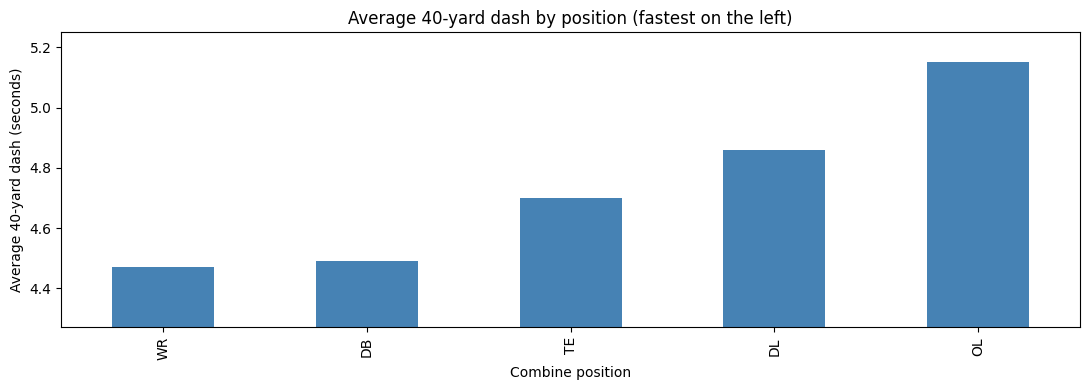

In [0]:
forty_by_position = (combine_results
                     .groupBy("combine_position")
                     .agg(F.round(F.avg("forty"), 2).alias("avg_forty"),
                          F.count("forty").alias("players_timed"))
                     .filter(F.col("avg_forty").isNotNull())
                     .orderBy("avg_forty")
                     .toPandas())

ax = forty_by_position.plot.bar(x="combine_position", y="avg_forty", legend=False,
                                color="steelblue", figsize=(11, 4))
ax.set_ylabel("Average 40-yard dash (seconds)")
ax.set_xlabel("Combine position")
ax.set_title("Average 40-yard dash by position (fastest on the left)")
ax.set_ylim(forty_by_position["avg_forty"].min() - 0.2, forty_by_position["avg_forty"].max() + 0.1)
plt.tight_layout()
plt.show()

## Part 2 — Build the modelling table and explore it

### 2.1 One row per player: features + target
**What it does:**
1. Joins Combine results (the **features**) with career results (the **target**) on `nfl_id`.
2. Converts all measurement columns to numbers.
3. Creates the target column `tg_career_start` (career games started).

**What to look for:** the number of players with both Combine data and a career record.

In [0]:
# Drill results stored as text → need try_cast
DRILL_COLUMNS = ["ten_yd_split", "forty", "vertical", "broad_jump",
                 "three_cone", "short_shuttle", "bench_reps"]
# Body measurements and scores already stored as numbers → simple cast to double
BODY_COLUMNS  = ["combine_height", "combine_weight", "hand_size", "arm_length",
                 "wing_span", "ngs_athleticism_score", "draft_year"]
ALL_NUMERIC   = DRILL_COLUMNS + BODY_COLUMNS

career = tables["player_career_successes"].select("nfl_id", "career_games_started")
model_df = tables["combine_results"].join(career, on="nfl_id", how="inner")

for c in DRILL_COLUMNS:
    model_df = model_df.withColumn(c, F.expr(f"try_cast({c} AS DOUBLE)"))
for c in BODY_COLUMNS:
    model_df = model_df.withColumn(c, F.col(c).cast("double"))

model_df = (model_df
            .withColumn(TARGET, F.col("career_games_started").cast("double"))
            .filter(F.col(TARGET).isNotNull())
            .select("nfl_id", "combine_position", *ALL_NUMERIC, TARGET))

print("Players in the modelling table:", model_df.count())
model_df.printSchema()

Players in the modelling table: 510
root
 |-- nfl_id: long (nullable = true)
 |-- combine_position: string (nullable = true)
 |-- ten_yd_split: double (nullable = true)
 |-- forty: double (nullable = true)
 |-- vertical: double (nullable = true)
 |-- broad_jump: double (nullable = true)
 |-- three_cone: double (nullable = true)
 |-- short_shuttle: double (nullable = true)
 |-- bench_reps: double (nullable = true)
 |-- combine_height: double (nullable = true)
 |-- combine_weight: double (nullable = true)
 |-- hand_size: double (nullable = true)
 |-- arm_length: double (nullable = true)
 |-- wing_span: double (nullable = true)
 |-- ngs_athleticism_score: double (nullable = true)
 |-- draft_year: double (nullable = true)
 |-- tg_career_start: double (nullable = true)



### 2.2 Missing data after casting — and which features to keep
**What it does:** charts the % of missing values per column, then applies one simple rule: **if more than half the players skipped a drill, leave it out**. Filling in more than half the values would mean inventing most of the data.

**What to look for:** `three_cone`, `short_shuttle` and `bench_reps` are mostly missing (many players skip them). Body measurements are almost complete.

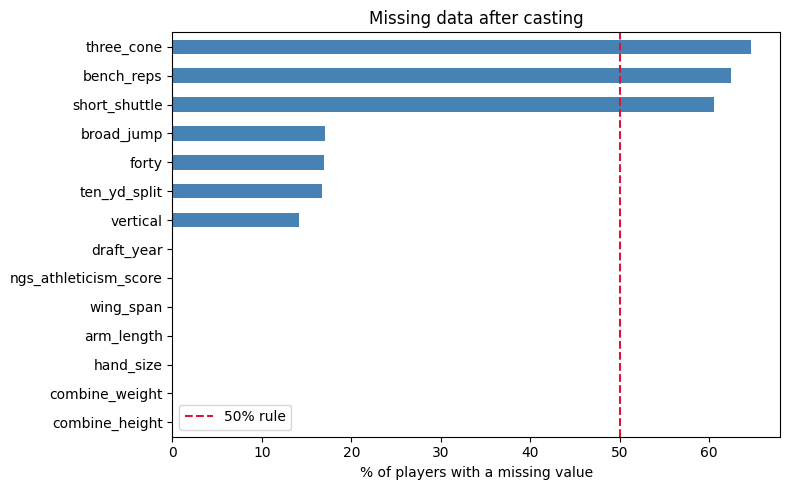

Dropped (more than 50% missing): ['three_cone', 'short_shuttle', 'bench_reps']
Features used in the model:      ['ten_yd_split', 'forty', 'vertical', 'broad_jump', 'combine_height', 'combine_weight', 'hand_size', 'arm_length', 'wing_span', 'ngs_athleticism_score', 'draft_year']


In [0]:
missing = null_percent(model_df, ALL_NUMERIC)

missing_chart = pd.Series(missing).sort_values()
ax = missing_chart.plot.barh(figsize=(8, 5), color="steelblue")
ax.axvline(50, color="crimson", linestyle="--", label="50% rule")
ax.set_xlabel("% of players with a missing value")
ax.set_title("Missing data after casting")
ax.legend()
plt.tight_layout()
plt.show()

FEATURES = [c for c in ALL_NUMERIC if missing[c] <= 50]
DROPPED  = [c for c in ALL_NUMERIC if missing[c] > 50]
print("Dropped (more than 50% missing):", DROPPED)
print("Features used in the model:     ", FEATURES)

### 2.3 Summary statistics
**What it does:** count, mean, spread, minimum, median and maximum of every feature and the target.

**What to look for:** features sit on very different scales (weight in hundreds of pounds, 40-yard dash around 4–5 seconds). Spark rescales them automatically before applying a penalty.

In [0]:
display(model_df.select(FEATURES + [TARGET]).summary("count", "mean", "stddev", "min", "50%", "max"))

summary,ten_yd_split,forty,vertical,broad_jump,combine_height,combine_weight,hand_size,arm_length,wing_span,ngs_athleticism_score,draft_year,tg_career_start
count,425,424,438,423,510,510,510,510,510,510,510,510
mean,1.6319999999999975,4.7335141509434004,33.81050228310502,118.15130023640661,74.5796568627451,248.38039215686274,9.571813725490196,32.41078431372549,78.46593137254902,72.45490196078431,2024.0254901960784,7.852941176470588
stddev,0.11557281458759279,0.3094487736839523,4.141178954580692,9.064842347707508,2.6281023635510317,53.254701848767475,0.6021783431693343,1.419285969981549,3.273242770851457,10.612338774901461,0.8084385826684088,11.466014580060824
min,1.46,4.28,23.0,93.0,68.125,154.0,8.0,28.5,69.0,51.0,2023.0,0.0
50%,1.59,4.62,34.0,120.0,75.0,245.0,9.5,32.375,78.5,73.0,2024.0,2.0
max,1.96,5.48,44.0,138.0,80.625,374.0,11.625,36.875,88.25,99.0,2025.0,50.0


### 2.4 What does the target look like?
**What to look for:** a right-skewed shape — many players start few or no games, a few start many. A few long careers will dominate the errors later.

Players who never started a game: 40.8%


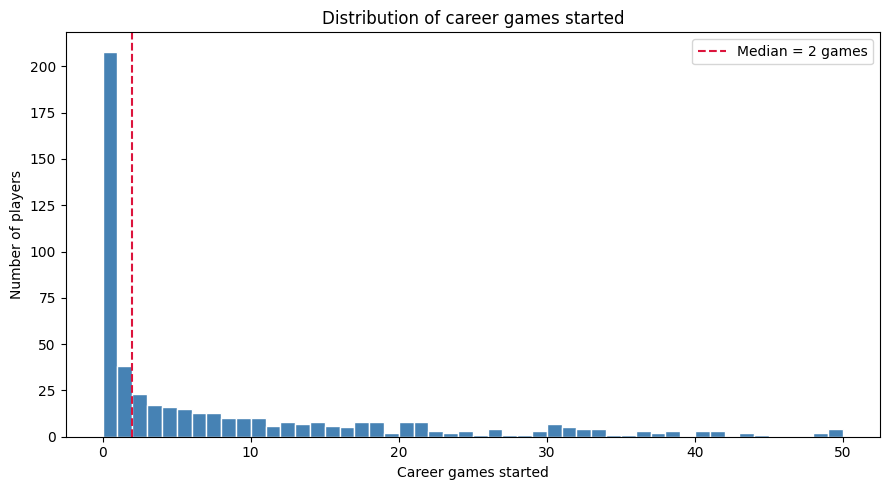

In [0]:
target_values = model_df.select(TARGET).toPandas()[TARGET]

share_zero = (target_values == 0).mean()
print(f"Players who never started a game: {share_zero:.1%}")

plt.figure(figsize=(9, 5))
plt.hist(target_values, bins=50, color="steelblue", edgecolor="white")
plt.axvline(target_values.median(), color="crimson", linestyle="--",
            label=f"Median = {target_values.median():.0f} games")
plt.xlabel("Career games started")
plt.ylabel("Number of players")
plt.title("Distribution of career games started")
plt.legend()
plt.tight_layout()
plt.show()

### 2.5 Does position matter?
**What to look for:** clear differences in average games started across positions. That is why position is one of the model's inputs.

combine_position,players,avg_games_started
DB,122,7.4
OL,121,11.0
DL,118,5.7
WR,107,7.4
TE,42,7.4


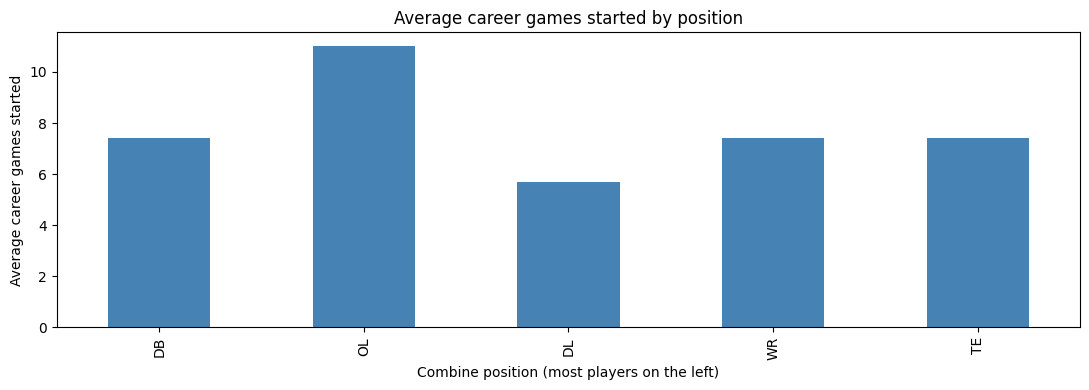

In [0]:
by_position = (model_df
               .groupBy("combine_position")
               .agg(F.count("nfl_id").alias("players"),
                    F.round(F.avg(TARGET), 1).alias("avg_games_started"))
               .orderBy(F.desc("players"))
               .toPandas())
display(by_position)

ax = by_position.plot.bar(x="combine_position", y="avg_games_started", legend=False,
                          color="steelblue", figsize=(11, 4))
ax.set_xlabel("Combine position (most players on the left)")
ax.set_ylabel("Average career games started")
ax.set_title("Average career games started by position")
plt.tight_layout()
plt.show()

### 2.6 Which features move together? (correlation heatmap)
**What it does:** correlation runs from −1 (move in opposite directions) to +1 (move together).

**What to look for:**
- Speed drills correlate strongly with each other, and heavier players run slower. Overlapping features are the reason Ridge and Lasso exist.
- The bottom row (`tg_career_start`) is pale: each feature on its own says little about career success. Expect a modest R².

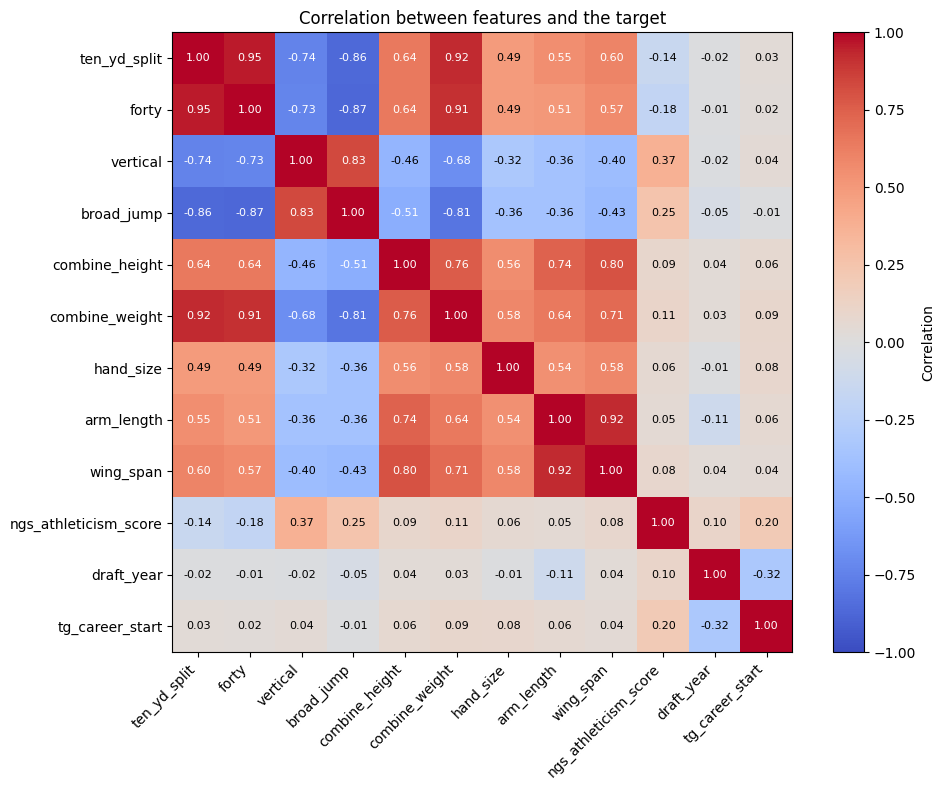

In [0]:
corr = model_df.select(FEATURES + [TARGET]).toPandas().corr()

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.5 else "black")
plt.colorbar(image, label="Correlation")
ax.set_title("Correlation between features and the target")
plt.tight_layout()
plt.show()

## Part 3 — MLflow experiments

| Setting | Values | Plain meaning |
|---|---|---|
| `regParam` | 0, 0.01, 0.1, 1.0 | Penalty strength. 0 = no penalty (plain OLS). |
| `elasticNetParam` = 0 | Ridge (L2) | Shrinks all coefficients towards zero |
| `elasticNetParam` = 1 | Lasso (L1) | Can set some coefficients exactly to zero |
| `elasticNetParam` = 0.5 | Elastic Net | Half Ridge, half Lasso |
| `solver` | normal / l-bfgs / auto | One-shot formula / step-by-step search / Spark chooses |

### 3.1 Split the data
**What it does:** 60% to learn from (**train**), 20% to choose the best setting (**validation**), 20% kept aside for one final check (**test**).

**Why three parts?** If we chose the best model using the test set, its test score would flatter it.

In [0]:
train_df, val_df, test_df = model_df.randomSplit([0.6, 0.2, 0.2], seed=SEED)

print(f"train: {train_df.count()}   validation: {val_df.count()}   test: {test_df.count()}")

train: 322   validation: 95   test: 93


### 3.2 The preparation pipeline
**What it does:** builds the steps that turn raw columns into the single `features` column Spark ML needs.

1. **Imputer** fills missing numbers with the median. It learns the median **from the training data only**, so no test information leaks into training.
2. **StringIndexer + OneHotEncoder** turn position text (e.g. `WR`) into 0/1 columns.
3. **VectorAssembler** packs everything into one `features` column.

Nothing is trained yet — this is the recipe.

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler

FILLED = [f"{c}_filled" for c in FEATURES]

prep_stages = [
    Imputer(inputCols=FEATURES, outputCols=FILLED, strategy="median"),
    StringIndexer(inputCol="combine_position", outputCol="position_index", handleInvalid="keep"),
    OneHotEncoder(inputCol="position_index", outputCol="position_onehot"),
    VectorAssembler(inputCols=FILLED + ["position_onehot"], outputCol="features"),
]

print("Pipeline steps:", [type(step).__name__ for step in prep_stages])

Pipeline steps: ['Imputer', 'StringIndexer', 'OneHotEncoder', 'VectorAssembler']


### 3.3 Run the 30 experiments
**What it does:** trains one model per combination of penalty, strength and solver. Each model gets its own **child run** inside one **parent run** called `NFL_LinReg_grid`.

For every run MLflow records:
- **params:** penalty, regParam, elasticNetParam, solver
- **metrics:** validation RMSE / MAE / R², fit time, iterations, number of zero coefficients, and one `coef_<feature>` per feature

**What to look for:** one line per run as it finishes. This cell takes **several minutes**. A failed run is recorded, not hidden.

In [0]:
from pyspark.ml.regression import LinearRegression

# Each setting is (penalty name, regParam, elasticNetParam)
settings = [("OLS", 0.0, 0.0)]
for penalty, mix in [("Ridge", 0.0), ("Lasso", 1.0), ("ElasticNet", 0.5)]:
    for strength in [0.01, 0.1, 1.0]:
        settings.append((penalty, strength, mix))
solvers = ["auto", "normal", "l-bfgs"]

fitted_models = {}   # run name → fitted model, kept in memory for Part 4

with mlflow.start_run(run_name=GRID_RUN_NAME):
    for penalty, reg_param, mix in settings:
        for solver in solvers:
            run_name = f"{penalty}_lam{reg_param:g}_{solver}"

            with mlflow.start_run(run_name=run_name, nested=True):
                mlflow.log_params({"penalty": penalty, "regParam": reg_param,
                                   "elasticNetParam": mix, "solver": solver})
                try:
                    # 1. Train
                    lr = LinearRegression(featuresCol="features", labelCol=TARGET,
                                          regParam=reg_param, elasticNetParam=mix, solver=solver)
                    start = time.time()
                    model = Pipeline(stages=prep_stages + [lr]).fit(train_df)
                    seconds = time.time() - start

                    # 2. Score on validation data
                    scores = evaluate(model, val_df)
                    lr_model = model.stages[-1]
                    coefs = lr_model.coefficients.toArray()

                    # 3. Record everything in MLflow
                    mlflow.log_metrics({
                        "val_rmse": scores["rmse"],
                        "val_mae": scores["mae"],
                        "val_r2": scores["r2"],
                        "fit_seconds": seconds,
                        "totalIterations": lr_model.summary.totalIterations,
                        "zero_coefficients": int((abs(coefs) < 1e-8).sum()),
                    })
                    # The first coefficients follow the FEATURES order (position columns come after)
                    mlflow.log_metrics({f"coef_{f}": float(coefs[i]) for i, f in enumerate(FEATURES)})
                    mlflow.set_tag("status", "succeeded")

                    fitted_models[run_name] = model
                    print(f"OK    {run_name:<24} val_rmse = {scores['rmse']:6.2f}   val_r2 = {scores['r2']:6.3f}")

                except Exception as error:
                    mlflow.set_tag("status", "failed")
                    mlflow.log_param("error", str(error)[:250])
                    print(f"FAIL  {run_name:<24} {str(error).splitlines()[0]}")

print(f"\n{len(fitted_models)} of {len(settings) * len(solvers)} runs succeeded.")

2026/11/03 00:25:29 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
2026/11/03 00:25:29 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
2026/11/03 00:25:41 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


OK    OLS_lam0_auto            val_rmse =   9.25   val_r2 =  0.111


2026/11/03 00:25:48 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


OK    OLS_lam0_normal          val_rmse =   9.25   val_r2 =  0.111


2026/11/03 00:25:57 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


OK    OLS_lam0_l-bfgs          val_rmse =   9.25   val_r2 =  0.111


... (48 outputs left out)

2026/11/03 00:29:05 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


OK    ElasticNet_lam1_auto     val_rmse =   9.12   val_r2 =  0.136


2026/11/03 00:29:10 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


OK    ElasticNet_lam1_normal   val_rmse =   9.12   val_r2 =  0.136
OK    ElasticNet_lam1_l-bfgs   val_rmse =   9.12   val_r2 =  0.136

30 of 30 runs succeeded.


### 3.4 Quick health check
**What it does:** asks MLflow (not Python memory) how many runs were saved.

**What to look for:** about 30 `succeeded`. Now open the **Experiment** icon in the right pane to see the runs in the MLflow UI.

In [0]:
parent_id, runs = get_grid_runs()

# MLflow's own lifecycle 'status' column (FINISHED/FAILED) collides with our
# 'status' tag (succeeded/failed) once get_grid_runs() strips the tags. prefix.
# Keep only the tag column so runs["status"] is a single Series.
runs = runs.loc[:, ~runs.columns.duplicated(keep="last")]

print("Parent run id:", parent_id)
print(runs["status"].value_counts().to_string())

Parent run id: d792a68f605d4b9ea72dd083521d89aa
status
succeeded    30


## Part 4 — Read the experiments

| Metric | Meaning | Better when |
|---|---|---|
| RMSE | Typical error in games started; big misses count extra | Lower |
| MAE | Average error in games started | Lower |
| R² | Share of variation the model explains (0 = no better than the average; below 0 = worse) | Higher |
| zero_coefficients | Features the model switched off | Higher = simpler |
| fit_seconds, totalIterations | Cost of training | Lower |

### 4.1 Leaderboard
**What to look for:** the top rows are usually very close. The winner is chosen on **validation** RMSE.

In [0]:
columns = ["run_name", "penalty", "regParam", "solver", "val_rmse", "val_mae", "val_r2",
           "zero_coefficients", "totalIterations", "fit_seconds"]

leaderboard = (runs[runs["status"] == "succeeded"][columns]
               .sort_values("val_rmse")
               .reset_index(drop=True))
display(leaderboard.round(3))

best_run_name = leaderboard.loc[0, "run_name"]
print(f"Best run on validation: {best_run_name}  (val_rmse = {leaderboard.loc[0, 'val_rmse']:.2f})")

run_name,penalty,regParam,solver,val_rmse,val_mae,val_r2,zero_coefficients,totalIterations,fit_seconds
ElasticNet_lam1_normal,ElasticNet,1.0,normal,9.123,6.977,0.136,10.0,19.0,2.66
ElasticNet_lam1_auto,ElasticNet,1.0,auto,9.123,6.977,0.136,10.0,19.0,2.911
ElasticNet_lam1_l-bfgs,ElasticNet,1.0,l-bfgs,9.123,6.977,0.136,10.0,27.0,4.064
Ridge_lam1_l-bfgs,Ridge,1.0,l-bfgs,9.159,7.012,0.129,0.0,26.0,5.44
Ridge_lam1_auto,Ridge,1.0,auto,9.16,7.012,0.129,0.0,0.0,3.433
Ridge_lam1_normal,Ridge,1.0,normal,9.16,7.012,0.129,0.0,0.0,3.413
Lasso_lam1_auto,Lasso,1.0,auto,9.168,7.092,0.128,13.0,21.0,2.899
Lasso_lam1_normal,Lasso,1.0,normal,9.168,7.092,0.128,13.0,21.0,3.443
Lasso_lam1_l-bfgs,Lasso,1.0,l-bfgs,9.168,7.092,0.128,13.0,21.0,5.046
Lasso_lam0.1_l-bfgs,Lasso,0.1,l-bfgs,9.19,7.067,0.123,3.0,65.0,8.33


Best run on validation: ElasticNet_lam1_normal  (val_rmse = 9.12)


### 4.2 Which penalty and strength work best?
**What it does:** for `solver = auto`, plots validation RMSE and R² against penalty strength, with plain OLS as a dashed line.

**What to look for:** the lowest point on the left chart is the best setting. If all lines sit on the OLS line, the penalty does not change accuracy much.

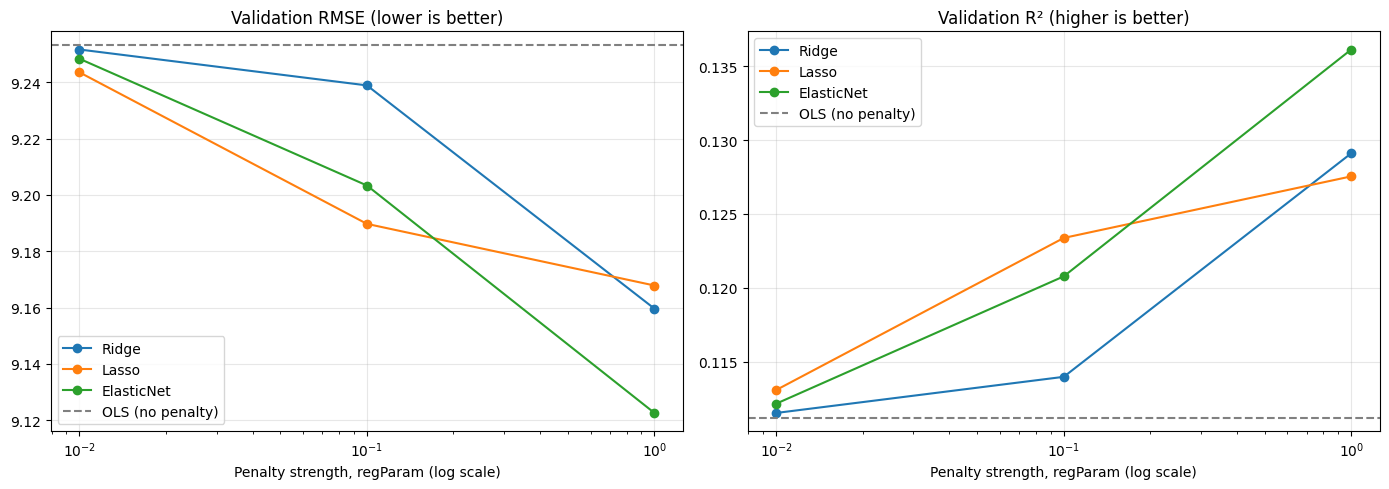

In [0]:
auto_runs = leaderboard[leaderboard["solver"] == "auto"]
ols = auto_runs[auto_runs["penalty"] == "OLS"].iloc[0]

fig, (ax_rmse, ax_r2) = plt.subplots(1, 2, figsize=(14, 5))
for penalty in ["Ridge", "Lasso", "ElasticNet"]:
    rows = auto_runs[auto_runs["penalty"] == penalty].sort_values("regParam")
    ax_rmse.plot(rows["regParam"], rows["val_rmse"], marker="o", label=penalty)
    ax_r2.plot(rows["regParam"], rows["val_r2"], marker="o", label=penalty)

ax_rmse.axhline(ols["val_rmse"], color="grey", linestyle="--", label="OLS (no penalty)")
ax_r2.axhline(ols["val_r2"], color="grey", linestyle="--", label="OLS (no penalty)")

for ax, title in [(ax_rmse, "Validation RMSE (lower is better)"),
                  (ax_r2, "Validation R² (higher is better)")]:
    ax.set_xscale("log")
    ax.set_xlabel("Penalty strength, regParam (log scale)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

mlflow.MlflowClient().log_figure(parent_id, fig, "penalty_strength_vs_error.png")

### 4.3 What did Lasso switch off? (coefficient paths)
**What it does:** follows each feature's coefficient as the penalty grows, starting from OLS on the left.

**What to look for:**
- **Lasso:** some lines drop to exactly zero — those features are switched off.
- **Ridge:** lines shrink towards zero but never reach it.

Coefficients are in each feature's own units, so compare the *shape* of each line, not their sizes.

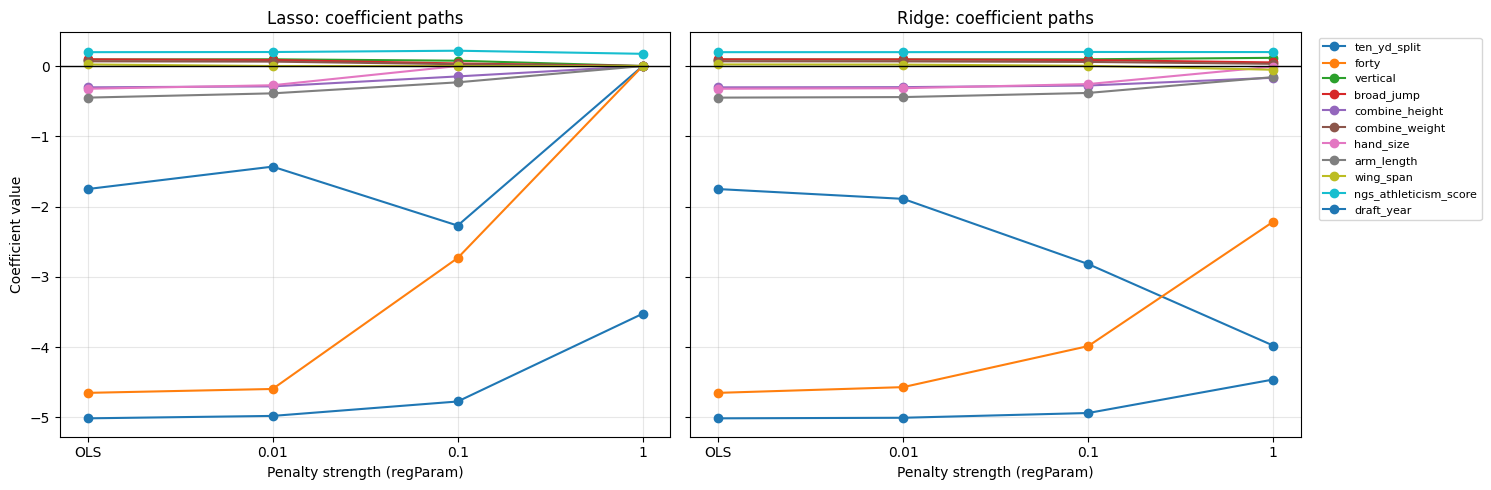

In [0]:
coef_columns = [f"coef_{f}" for f in FEATURES]
ok_auto = runs[(runs["status"] == "succeeded") & (runs["solver"] == "auto")]
ols_coefs = ok_auto[ok_auto["penalty"] == "OLS"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, penalty in zip(axes, ["Lasso", "Ridge"]):
    path = ok_auto[ok_auto["penalty"] == penalty].sort_values("regParam")
    x_labels = ["OLS"] + [f"{v:g}" for v in path["regParam"]]
    for col in coef_columns:
        values = [ols_coefs[col]] + list(path[col])
        ax.plot(range(len(values)), values, marker="o", label=col.replace("coef_", ""))
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(range(len(x_labels)))
    ax.set_xticklabels(x_labels)
    ax.set_xlabel("Penalty strength (regParam)")
    ax.set_title(f"{penalty}: coefficient paths")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Coefficient value")
axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

mlflow.MlflowClient().log_figure(parent_id, fig, "coefficient_paths_lasso_vs_ridge.png")

### 4.4 Do solvers change the answer or only the cost?
**What it does:** for Ridge at regParam 0.1, compares the three solvers side by side.

**What to look for:** almost identical RMSE, but different time and iterations. `normal` solves in one step, so it may show 0 iterations. The solver is an engineering choice, not a business one.

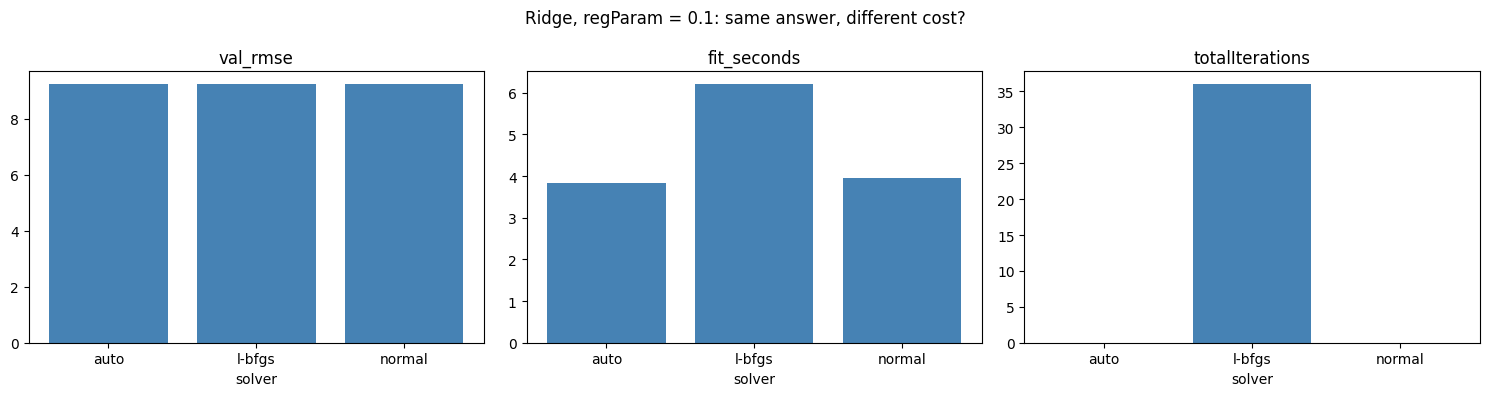

In [0]:
ridge = (leaderboard[(leaderboard["penalty"] == "Ridge") & (leaderboard["regParam"] == 0.1)]
         .sort_values("solver"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["val_rmse", "fit_seconds", "totalIterations"]):
    ax.bar(ridge["solver"], ridge[metric], color="steelblue")
    ax.set_title(metric)
    ax.set_xlabel("solver")
fig.suptitle("Ridge, regParam = 0.1: same answer, different cost?")
plt.tight_layout()
plt.show()

mlflow.MlflowClient().log_figure(parent_id, fig, "solver_comparison.png")

### 4.5 Final test, error chart and registration
**What it does:**
1. Takes the winning model and scores it **once** on the test set.
2. Plots predicted vs actual games started.
3. Saves the model in Unity Catalog so others can reuse it.

**What to look for:** test scores close to validation scores. A large gap means the winner was partly lucky on the validation data. Points far below the dashed line are long careers the model under-predicts.

Test set: RMSE = 11.82   MAE = 9.38   R² = 0.106


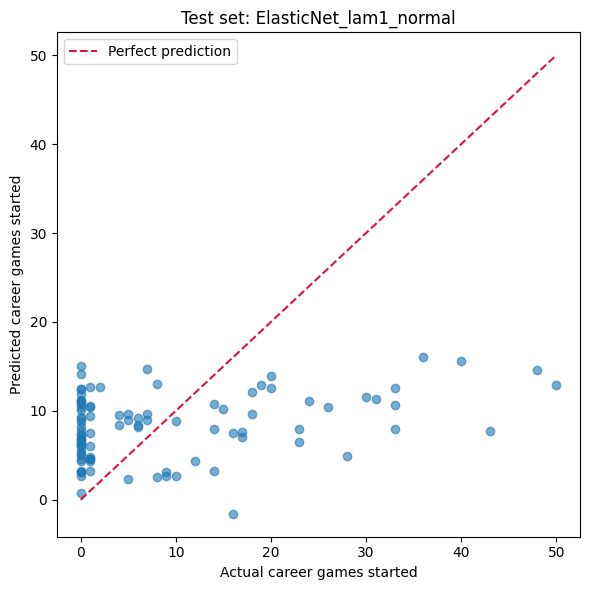

2026/11/03 00:41:55 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
2026/11/03 00:42:20 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /local_disk0/user_tmp_data/spark-e8c3df0f-56f6-4c2e-bd89-07/tmpdgmg4imj/model, flavor: spark). Fall back to return ['pyspark==4.3.0']. Set logging level to DEBUG to see the full traceback. 
Registered model 'nfl_bigdatabowl.nfl_2027.nfl_games_started_lr' already exists. Creating a new version of this model...


Uploading artifacts:   0%|          | 0/48 [00:00<?, ?it/s]

🔗 Created version '3' of model 'nfl_bigdatabowl.nfl_2027.nfl_games_started_lr': https://dbc-1e30501c-741f.cloud.databricks.com/explore/data/models/nfl_bigdatabowl/nfl_2027/nfl_games_started_lr/version/3?o=7474651698890531


Model registered in Unity Catalog as nfl_bigdatabowl.nfl_2027.nfl_games_started_lr


In [0]:
from mlflow.models import infer_signature

best_model = fitted_models[best_run_name]   # if this fails, the cluster restarted: re-run 3.3
test_scores = evaluate(best_model, test_df)
print(f"Test set: RMSE = {test_scores['rmse']:.2f}   MAE = {test_scores['mae']:.2f}   R² = {test_scores['r2']:.3f}")

# Predicted vs actual chart
INPUT_COLUMNS = FEATURES + ["combine_position"]
test_predictions = best_model.transform(test_df).select(*INPUT_COLUMNS, TARGET, "prediction").toPandas()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test_predictions[TARGET], test_predictions["prediction"], alpha=0.6)
top = max(test_predictions[TARGET].max(), test_predictions["prediction"].max())
ax.plot([0, top], [0, top], "--", color="crimson", label="Perfect prediction")
ax.set_xlabel("Actual career games started")
ax.set_ylabel("Predicted career games started")
ax.set_title(f"Test set: {best_run_name}")
ax.legend()
plt.tight_layout()
plt.show()

# Save the winner: test scores, chart and the model itself
sample = test_predictions.head(5)
signature = infer_signature(sample[INPUT_COLUMNS], sample[["prediction"]])

with mlflow.start_run(run_name=f"BEST_{best_run_name}"):
    mlflow.log_param("chosen_from", best_run_name)
    mlflow.log_metrics({"test_rmse": test_scores["rmse"],
                        "test_mae": test_scores["mae"],
                        "test_r2": test_scores["r2"]})
    mlflow.log_figure(fig, "test_predicted_vs_actual.png")
    mlflow.spark.log_model(best_model, "model", signature=signature,
                           dfs_tmpdir=TMP_VOLUME, registered_model_name=MODEL_NAME)

print("Model registered in Unity Catalog as", MODEL_NAME)

### 4.6 Is the model better than guessing the average?
**What it does:** builds the simplest possible "model": predict the training average for every player. Every real model must beat this **baseline**.

**What to look for:** if the baseline's RMSE is close to (or better than) the best model's, Combine numbers alone add little predictive value. That is a valid business finding.

In [0]:
train_average = float(train_df.agg(F.avg(TARGET)).first()[0])
baseline_predictions = test_df.withColumn("prediction", F.lit(train_average))

baseline_scores = {}
for metric in ["rmse", "mae", "r2"]:
    evaluator = RegressionEvaluator(labelCol=TARGET, predictionCol="prediction", metricName=metric)
    baseline_scores[metric] = evaluator.evaluate(baseline_predictions)

comparison = pd.DataFrame({
    "model": [best_run_name, f"Guess the average ({train_average:.1f} games)"],
    "test_rmse": [test_scores["rmse"], baseline_scores["rmse"]],
    "test_mae":  [test_scores["mae"],  baseline_scores["mae"]],
    "test_r2":   [test_scores["r2"],   baseline_scores["r2"]],
}).round(3)
display(comparison)

with mlflow.start_run(run_name="BASELINE_train_average"):
    mlflow.log_metrics({f"test_{k}": v for k, v in baseline_scores.items()})

model,test_rmse,test_mae,test_r2
ElasticNet_lam1_normal,11.82,9.381,0.106
Guess the average (7.8 games),12.593,9.552,-0.014


2026/11/03 00:44:01 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


## Decide — business recommendation (150 words, in your README)
1. Which penalty and strength won? Did the solver change the answer or only the cost?
2. Which drills did Lasso switch off? What does that mean for a scout's time at the Combine?
3. Did the model beat "guess the average"? What two **non-Combine** data sources would you add before a general manager relies on it?

**Before you leave:** Git dialog → **Commit & Push**.